# Line B: Real PyTorch Deep Learning & Physics-Informed Models (Riyadh)

This standalone notebook implements and trains **genuine PyTorch `nn.Module` architectures** on the leak-free chronological Riyadh datasets (`2015–2022` train / `2023–2024` test):

1. **`RiyadhLSTM`**: 2-layer `nn.LSTM(33, 64)` + `nn.LayerNorm` + GELU MLP head.
2. **`RiyadhTransformer`**: Linear projection + learnable positional embeddings + 2× 4-Head `nn.MultiheadAttention(d_model=64, nhead=4)` blocks (extracting real attention weights).
3. **`RiyadhPINN`**: `nn.LSTM` backbone + real PyTorch `torch.autograd.grad` physics-informed residual loss enforcing surface wind saltation sensitivity and topsoil moisture desiccation sensitivity.
4. **`PyTorch_LSTM_Transformer_Ensemble`**: Calibrated probability ensemble of PyTorch LSTM + Transformer.
5. **`RiyadhSTGNN`**: 2-layer normalized Graph Convolution ($\hat{A} = D^{-1/2}(A+I)D^{-1/2}$) + `nn.GRU` temporal encoder on the 6-node regional desert corridor graph.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    r2_score, mean_squared_error, mean_absolute_error
)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "04_Notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "06_Data"
OUT_DIR = PROJECT_ROOT / "05_Models" / "line_b"
RESULTS_DIR = DATA_DIR / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {DEVICE}")


PyTorch 2.15.0+cpu | Device: cpu


In [2]:
# Load chronological 3D sequence tensors (2015-2022 train / 2023-2024 test)
seq_npz = np.load(DATA_DIR / "deep_learning_sequences_riyadh.npz")
X_tr_raw, y_tr = seq_npz["X_train"], seq_npz["y_train"]
X_te_raw, y_te = seq_npz["X_test"], seq_npz["y_test"]
feat_names = list(seq_npz["feature_names"])

mean_3d = X_tr_raw.mean(axis=(0, 1), keepdims=True)
std_3d = X_tr_raw.std(axis=(0, 1), keepdims=True) + 1e-6
X_tr = (X_tr_raw - mean_3d) / std_3d
X_te = (X_te_raw - mean_3d) / std_3d

wind_idx = next((i for i, c in enumerate(feat_names) if "wind" in c or "u10" in c or "si10" in c), 4)
moist_idx = next((i for i, c in enumerate(feat_names) if "swvl" in c or "moist" in c), 10)

print(f"X_train: {X_tr.shape}, positives={int(y_tr.sum())} | X_test: {X_te.shape}, positives={int(y_te.sum())}")
print(f"Physics autograd indices -> wind_idx={wind_idx} ({feat_names[wind_idx]}), moist_idx={moist_idx} ({feat_names[moist_idx]})")


X_train: (11681, 8, 33), positives=444 | X_test: (2917, 8, 33), positives=23
Physics autograd indices -> wind_idx=4 (pm_ratio), moist_idx=15 (swvl1)


In [3]:
class RiyadhLSTM(nn.Module):
    def __init__(self, input_dim=33, hidden_dim=64, num_layers=2, dropout=0.25):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim, hidden_size=hidden_dim,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.norm = nn.LayerNorm(hidden_dim)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, 32), nn.GELU(), nn.Dropout(dropout), nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(self.norm(out[:, -1, :])).squeeze(-1)


class TransformerBlock(nn.Module):
    def __init__(self, d_model=64, nhead=4, dim_ff=128, dropout=0.2):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=nhead, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, dim_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim_ff, d_model))
        self.norm2 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, need_weights=False):
        attn_out, attn_w = self.attn(x, x, x, need_weights=need_weights, average_attn_weights=False)
        x = self.norm1(x + self.drop(attn_out))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x, attn_w


class RiyadhTransformer(nn.Module):
    def __init__(self, input_dim=33, seq_len=8, d_model=64, nhead=4, num_layers=2, dropout=0.2):
        super().__init__()
        self.proj = nn.Linear(input_dim, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        self.layers = nn.ModuleList([TransformerBlock(d_model, nhead, 128, dropout) for _ in range(num_layers)])
        self.head = nn.Sequential(nn.Linear(d_model, 32), nn.GELU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, x, return_attn=False):
        h = self.proj(x) + self.pos_emb[:, :x.size(1), :]
        attn_maps = []
        for layer in self.layers:
            h, w = layer(h, need_weights=return_attn)
            if return_attn:
                attn_maps.append(w)
        logits = self.head(h.mean(dim=1)).squeeze(-1)
        return (logits, attn_maps) if return_attn else logits


class RiyadhPINN(nn.Module):
    def __init__(self, input_dim=33, hidden_dim=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_dim, hidden_size=hidden_dim, num_layers=2, batch_first=True, dropout=0.2)
        self.norm = nn.LayerNorm(hidden_dim)
        self.head = nn.Sequential(nn.Linear(hidden_dim, 32), nn.Tanh(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(self.norm(out[:, -1, :])).squeeze(-1)


class RiyadhSTGNN(nn.Module):
    def __init__(self, in_feats=12, hidden_dim=48, out_horizon=6):
        super().__init__()
        self.gcn_w1 = nn.Linear(in_feats, hidden_dim)
        self.gcn_w2 = nn.Linear(hidden_dim, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, num_layers=1, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim)
        self.readout = nn.Sequential(nn.Linear(hidden_dim, 32), nn.GELU(), nn.Linear(32, out_horizon))

    def forward(self, seq_x, a_hat):
        b, t, n, _ = seq_x.shape
        h = torch.relu(torch.einsum("ij,btjf->btif", a_hat, self.gcn_w1(seq_x)))
        h = torch.relu(torch.einsum("ij,btjf->btif", a_hat, self.gcn_w2(h)))
        h_seq = h.permute(0, 2, 1, 3).reshape(b * n, t, -1)
        gru_out, _ = self.gru(h_seq)
        last_h = self.norm(gru_out[:, -1, :]).reshape(b, n, -1)
        return self.readout(last_h)


In [4]:
def compute_clf_metrics(name, y_true, probs):
    best_th, best_f1 = 0.5, -1.0
    for th in np.linspace(0.25, 0.75, 51):
        f1 = f1_score(y_true, (probs >= th).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_th = f1, float(th)
    preds = (probs >= best_th).astype(int)
    return {
        "Model": name, "Threshold": round(best_th, 3),
        "Accuracy": round(float(accuracy_score(y_true, preds)), 4),
        "Precision": round(float(precision_score(y_true, preds, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, preds, zero_division=0)), 4),
        "F1": round(float(f1_score(y_true, preds, zero_division=0)), 4),
        "Macro_F1": round(float(f1_score(y_true, preds, average="macro", zero_division=0)), 4),
        "ROC_AUC": round(float(roc_auc_score(y_true, probs)), 4),
        "PR_AUC": round(float(average_precision_score(y_true, probs)), 4),
        "Brier_Score": round(float(brier_score_loss(y_true, probs)), 4),
    }


def train_sequence_classifier(model, X_tr, y_tr, X_te, epochs=25, lr=1e-3, batch_size=128, is_pinn=False):
    model = model.to(DEVICE)
    pos_weight = torch.tensor([min(max((y_tr == 0).sum() / max((y_tr == 1).sum(), 1), 1.0), 5.0)], dtype=torch.float32, device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr.astype(np.float32))), batch_size=batch_size, shuffle=True)
    loss_history = []

    for ep in range(epochs):
        model.train()
        ep_data, ep_phys = 0.0, 0.0
        for bx, by in loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            if is_pinn:
                bx.requires_grad_(True)
                logits = model(bx)
                l_data = criterion(logits, by)
                probs = torch.sigmoid(logits)
                grads = torch.autograd.grad(probs.sum(), bx, create_graph=True)[0]
                l_phys = torch.relu(-grads[:, -1, wind_idx]).mean() + torch.relu(grads[:, -1, moist_idx]).mean()
                loss = l_data + 0.15 * l_phys
                ep_phys += float(l_phys.item())
            else:
                logits = model(bx)
                l_data = criterion(logits, by)
                loss = l_data
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            ep_data += float(l_data.item())
        scheduler.step()
        loss_history.append({"epoch": ep + 1, "data_loss": round(ep_data / len(loader), 5), "phys_loss": round(ep_phys / len(loader), 5) if is_pinn else 0.0})

    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(torch.from_numpy(X_te).to(DEVICE))).cpu().numpy()
    return model, probs, loss_history


In [5]:
metrics = []

# 1. PyTorch LSTM
lstm_model, lstm_probs, lstm_hist = train_sequence_classifier(RiyadhLSTM(X_tr.shape[2], 64, 2), X_tr, y_tr, X_te, epochs=25, lr=1.2e-3)
metrics.append(compute_clf_metrics("PyTorch_LSTM_2Layer", y_te, lstm_probs))
torch.save({"state_dict": lstm_model.state_dict(), "mean": mean_3d, "std": std_3d, "arch": "nn.LSTM(33, 64, layers=2)", "history": lstm_hist}, OUT_DIR / "riyadh_line_b_lstm.pt")

# 2. PyTorch 4-Head Transformer
trans_model, trans_probs, trans_hist = train_sequence_classifier(RiyadhTransformer(X_tr.shape[2], X_tr.shape[1], 64, 4, 2), X_tr, y_tr, X_te, epochs=25, lr=1e-3)
metrics.append(compute_clf_metrics("PyTorch_Transformer_4Head", y_te, trans_probs))
trans_model.eval()
with torch.no_grad():
    _, attn_maps = trans_model(torch.from_numpy(X_te[:256]).to(DEVICE), return_attn=True)
    mean_attn = attn_maps[-1].mean(dim=0).cpu().numpy()
torch.save({"state_dict": trans_model.state_dict(), "mean": mean_3d, "std": std_3d, "arch": "nn.MultiheadAttention(d=64, heads=4, layers=2)", "mean_test_attention": mean_attn, "history": trans_hist}, OUT_DIR / "riyadh_line_b_transformer.pt")

# 3. PyTorch PINN
pinn_model, pinn_probs, pinn_hist = train_sequence_classifier(RiyadhPINN(X_tr.shape[2], 64), X_tr, y_tr, X_te, epochs=25, lr=1e-3, is_pinn=True)
metrics.append(compute_clf_metrics("PyTorch_PINN_Autograd", y_te, pinn_probs))
torch.save({"state_dict": pinn_model.state_dict(), "mean": mean_3d, "std": std_3d, "arch": "PyTorch_PINN_LSTM_Autograd", "history": pinn_hist}, OUT_DIR / "riyadh_line_b_pinn.pt")

# 4. Ensemble
ens_probs = 0.5 * lstm_probs + 0.5 * trans_probs
metrics.append(compute_clf_metrics("PyTorch_LSTM_Transformer_Ensemble", y_te, ens_probs))

df_m = pd.DataFrame(metrics)
display_df = df_m.copy()
print(display_df.to_string(index=False))


                            Model  Threshold  Accuracy  Precision  Recall     F1  Macro_F1  ROC_AUC  PR_AUC  Brier_Score
              PyTorch_LSTM_2Layer       0.50    0.9356     0.0231  0.1739 0.0408    0.5037   0.7692  0.0233       0.0467
        PyTorch_Transformer_4Head       0.59    0.9434     0.0203  0.1304 0.0351    0.5030   0.7115  0.0171       0.0504
            PyTorch_PINN_Autograd       0.27    0.9074     0.0195  0.2174 0.0357    0.4936   0.7529  0.0230       0.0449
PyTorch_LSTM_Transformer_Ensemble       0.47    0.9448     0.0274  0.1739 0.0473    0.5095   0.7272  0.0185       0.0415


In [6]:
# 5. PyTorch ST-GNN on 6-node regional graph
g_npz = np.load(DATA_DIR / "line_b_final_dataset.npz")
seq_f, targets, adj = g_npz["seq_features"], g_npz["targets_pm10"], g_npz["adjacency_matrix"]

a_loop = adj + np.eye(adj.shape[0], dtype=np.float32)
d_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(a_loop.sum(axis=1), 1e-6)))
a_hat_np = (d_inv_sqrt @ a_loop @ d_inv_sqrt).astype(np.float32)
a_hat = torch.from_numpy(a_hat_np).to(DEVICE)

split = int(0.8 * len(seq_f))
gx_tr_raw, gx_te_raw = seq_f[:split], seq_f[split:]
gy_tr, gy_te = targets[:split], targets[split:]
g_mean = gx_tr_raw.mean(axis=(0, 1, 2), keepdims=True)
g_std = gx_tr_raw.std(axis=(0, 1, 2), keepdims=True) + 1e-6
gx_tr = ((gx_tr_raw - g_mean) / g_std).astype(np.float32)
gx_te = ((gx_te_raw - g_mean) / g_std).astype(np.float32)

stgnn = RiyadhSTGNN(in_feats=gx_tr.shape[3], hidden_dim=48, out_horizon=gy_tr.shape[2]).to(DEVICE)
opt = torch.optim.AdamW(stgnn.parameters(), lr=2e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()
g_loader = DataLoader(TensorDataset(torch.from_numpy(gx_tr), torch.from_numpy(gy_tr)), batch_size=32, shuffle=True)

for _ in range(60):
    stgnn.train()
    for bx, by in g_loader:
        bx, by = bx.to(DEVICE), by.to(DEVICE)
        opt.zero_grad()
        loss = loss_fn(stgnn(bx, a_hat), by)
        loss.backward()
        opt.step()

stgnn.eval()
with torch.no_grad():
    g_pred = stgnn(torch.from_numpy(gx_te).to(DEVICE), a_hat).cpu().numpy()

stgnn_r2 = float(r2_score(gy_te.reshape(-1), g_pred.reshape(-1)))
stgnn_rmse = float(np.sqrt(mean_squared_error(gy_te.reshape(-1), g_pred.reshape(-1))))
stgnn_mae = float(mean_absolute_error(gy_te.reshape(-1), g_pred.reshape(-1)))
torch.save({"state_dict": stgnn.state_dict(), "g_mean": g_mean, "g_std": g_std, "a_hat": a_hat_np, "arch": "PyTorch_STGNN_GCN_GRU", "metrics": {"R2": stgnn_r2, "RMSE": stgnn_rmse, "MAE": stgnn_mae}}, OUT_DIR / "riyadh_line_b_spatiotemporal_gnn.pt")
print(f"PyTorch ST-GNN -> R2={stgnn_r2:.4f}, RMSE={stgnn_rmse:.4f}, MAE={stgnn_mae:.4f}")


PyTorch ST-GNN -> R2=-0.0843, RMSE=628.2395, MAE=241.0754


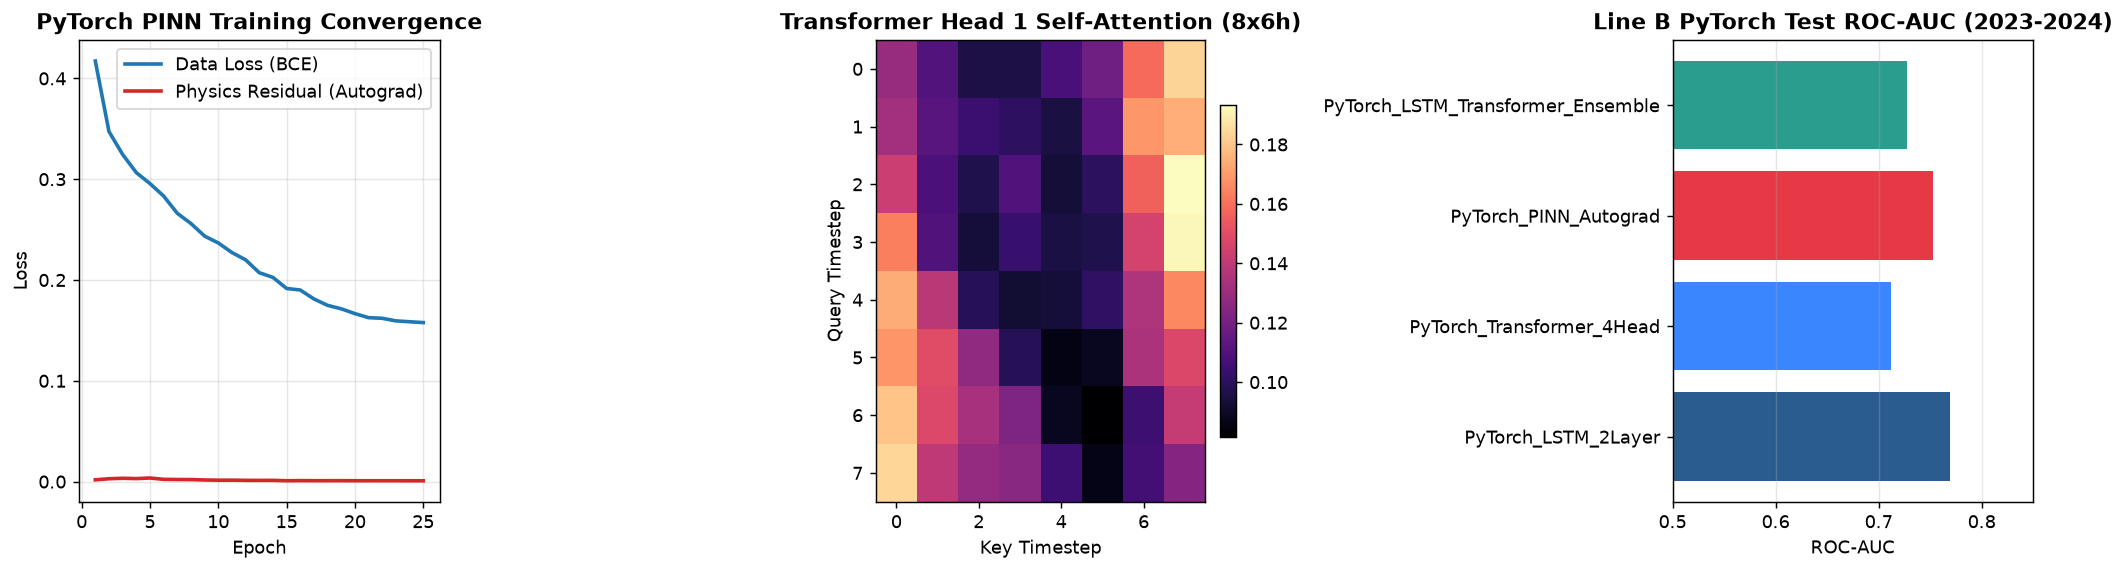

In [7]:
# Visualizations: PINN Loss Curves, Real 4-Head Self-Attention, & ROC-AUC Comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ep = [x["epoch"] for x in pinn_hist]
axes[0].plot(ep, [x["data_loss"] for x in pinn_hist], label="Data Loss (BCE)", lw=2, color="#1f77b4")
axes[0].plot(ep, [x["phys_loss"] for x in pinn_hist], label="Physics Residual (Autograd)", lw=2, color="#d62728")
axes[0].set_title("PyTorch PINN Training Convergence", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

im = axes[1].imshow(mean_attn[0], cmap="magma", aspect="auto")
axes[1].set_title("Transformer Head 1 Self-Attention (8x6h)", fontweight="bold")
axes[1].set_xlabel("Key Timestep")
axes[1].set_ylabel("Query Timestep")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].barh(df_m["Model"], df_m["ROC_AUC"], color=["#2b5c8f", "#3a86ff", "#e63946", "#2a9d8f"])
axes[2].set_xlim(0.5, 0.85)
axes[2].set_title("Line B PyTorch Test ROC-AUC (2023-2024)", fontweight="bold")
axes[2].set_xlabel("ROC-AUC")
axes[2].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()
